In [3]:
import pandas as pd
import matplotlib.pyplot as plt


In [4]:
# Đọc file Numerics
numerics = pd.read_csv('bidmc_csv/bidmc_01_Numerics.csv')

# Đọc file Signals
signals = pd.read_csv('bidmc_csv/bidmc_01_Signals.csv')

# Đọc file Breaths
breaths = pd.read_csv('bidmc_csv/bidmc_01_Breaths.csv')

# Hiển thị vài dòng đầu tiên
print(numerics.head())
print(signals.head())
print(breaths.head())


   Time [s]   HR   PULSE   RESP   SpO2
0         0   94    93.0     25   97.0
1         1   94    93.0     25   97.0
2         2   94    93.0     25   97.0
3         3   92    93.0     26   97.0
4         4   93    93.0     26   97.0
   Time [s]     RESP    PLETH        V      AVR       II
0     0.000  0.35386  0.43597  0.52549  0.30392  0.72549
1     0.008  0.35679  0.43206  0.51961  0.33529  0.67059
2     0.016  0.35875  0.42815  0.51569  0.37451  0.60980
3     0.024  0.36168  0.42424  0.50588  0.41961  0.55098
4     0.032  0.36364  0.42131  0.50980  0.44902  0.50000
   breaths ann1 [signal sample no]   breaths ann2 [signal sample no]
0                              189                               187
1                              476                               472
2                              737                               747
3                             1037                              1042
4                             1324                              1322


In [7]:
# Kiểm tra kiểu dữ liệu từng cột
print("Numerics Data Types:\n", numerics.dtypes)
print("\nSignals Data Types:\n", signals.dtypes)
print("\nBreaths Data Types:\n", breaths.dtypes)


Numerics Data Types:
 Time [s]      int64
 HR           int64
 PULSE      float64
 RESP         int64
 SpO2       float64
dtype: object

Signals Data Types:
 Time [s]    float64
 RESP       float64
 PLETH      float64
 V          float64
 AVR        float64
 II         float64
dtype: object

Breaths Data Types:
 breaths ann1 [signal sample no]     int64
 breaths ann2 [signal sample no]    int64
dtype: object


In [8]:
# Đổi tên cột thời gian để dễ xử lý
numerics.rename(columns={'Time [s]': 'Time'}, inplace=True)
signals.rename(columns={'Time [s]': 'Time'}, inplace=True)

In [13]:
# Xóa khoảng trắng ở đầu/cuối tên cột
numerics.columns = numerics.columns.str.strip()
signals.columns = signals.columns.str.strip()
breaths.columns = breaths.columns.str.strip()


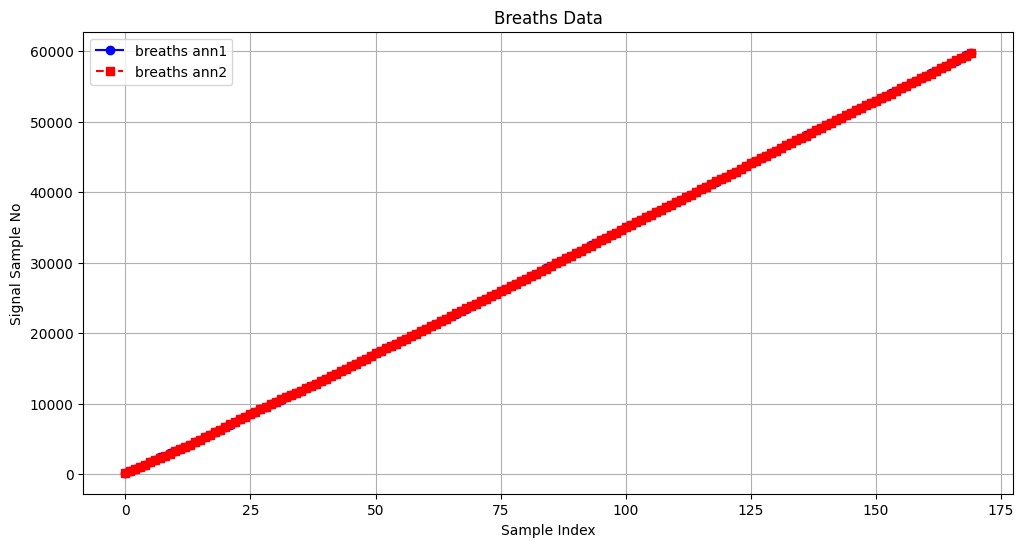

Text(0.5, 1.0, 'Signals Data')

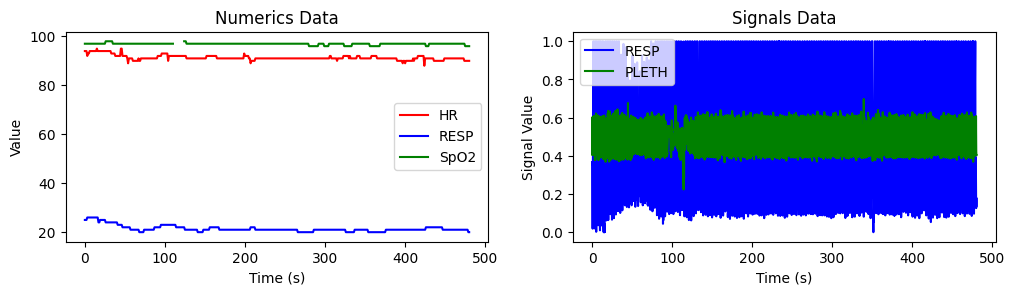

In [33]:
# Vẽ biểu đồ thống kê ban đầu
plt.figure(figsize=(12, 6))
plt.plot(breaths.index, breaths["breaths ann1 [signal sample no]"], label="breaths ann1", marker="o", linestyle="-", color="b")
plt.plot(breaths.index, breaths["breaths ann2 [signal sample no]"], label="breaths ann2", marker="s", linestyle="--", color="r")
plt.xlabel("Sample Index")
plt.ylabel("Signal Sample No")
plt.title("Breaths Data")
plt.legend()
plt.grid()
plt.show()

plt.figure(figsize=(12, 6))
plt.subplot(2, 2, 1)
plt.plot(numerics['Time'], numerics['HR'], label='HR', color='r')
plt.plot(numerics['Time'], numerics['RESP'], label='RESP', color='b')
plt.plot(numerics['Time'], numerics['SpO2'], label='SpO2', color='g')
plt.xlabel('Time (s)')
plt.ylabel('Value')
plt.legend()
plt.title('Numerics Data')

plt.subplot(2, 2, 2)
plt.plot(signals['Time'], signals['RESP'], label='RESP', color='b')
plt.plot(signals['Time'], signals['PLETH'], label='PLETH', color='g')
plt.xlabel('Time (s)')
plt.ylabel('Signal Value')
plt.legend()
plt.title('Signals Data')

In [17]:
import seaborn as sns
from sklearn.preprocessing import MinMaxScaler

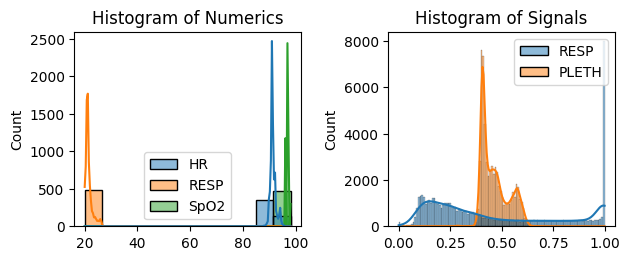

In [18]:
# Vẽ histogram để xem phân bố dữ liệu
plt.subplot(2, 2, 3)
sns.histplot(numerics[['HR', 'RESP', 'SpO2']], kde=True)
plt.title('Histogram of Numerics')

plt.subplot(2, 2, 4)
sns.histplot(signals[['RESP', 'PLETH']], kde=True)
plt.title('Histogram of Signals')

plt.tight_layout()
plt.show()


In [35]:
# **Chuẩn hóa dữ liệu**
scaler = MinMaxScaler()

# Chuẩn hóa dữ liệu bằng MinMaxScaler
breaths_normalized = scaler.fit_transform(breaths)
breaths_normalized = pd.DataFrame(breaths_normalized, columns=breaths.columns)

# Chuẩn hóa Numerics
numerics_scaled = numerics.copy()
numerics_scaled[['HR', 'PULSE', 'RESP', 'SpO2']] = scaler.fit_transform(numerics[['HR', 'PULSE', 'RESP', 'SpO2']])

# Chuẩn hóa Signals
signals_scaled = signals.copy()
signals_scaled[['RESP', 'PLETH', 'V', 'AVR', 'II']] = scaler.fit_transform(signals[['RESP', 'PLETH', 'V', 'AVR', 'II']])


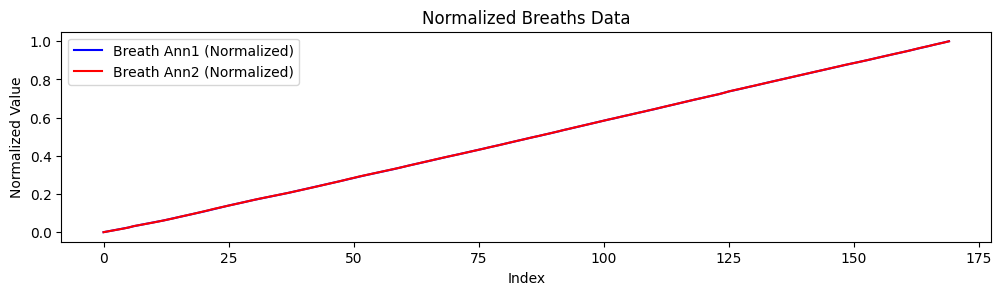

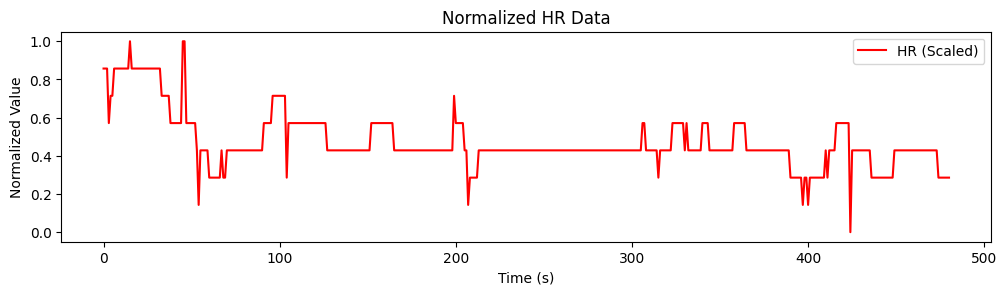

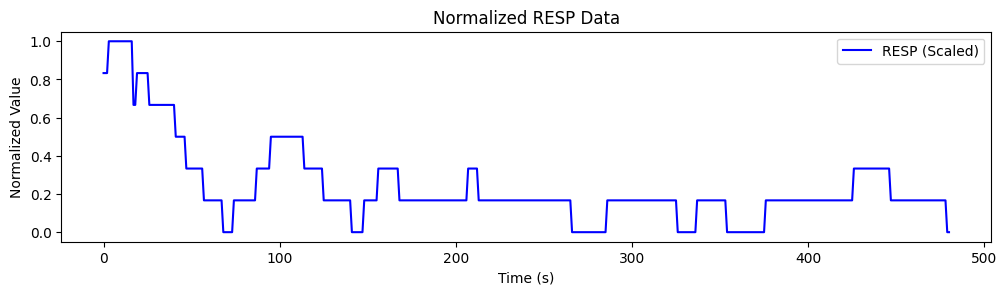

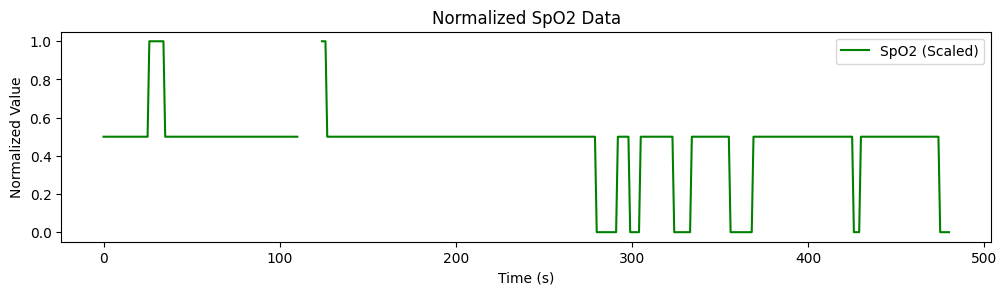

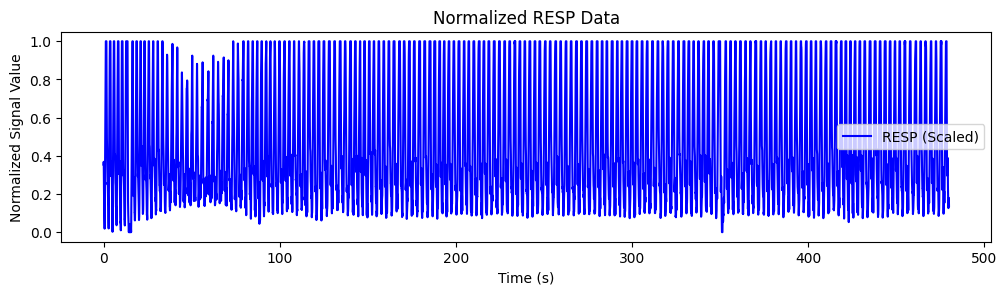

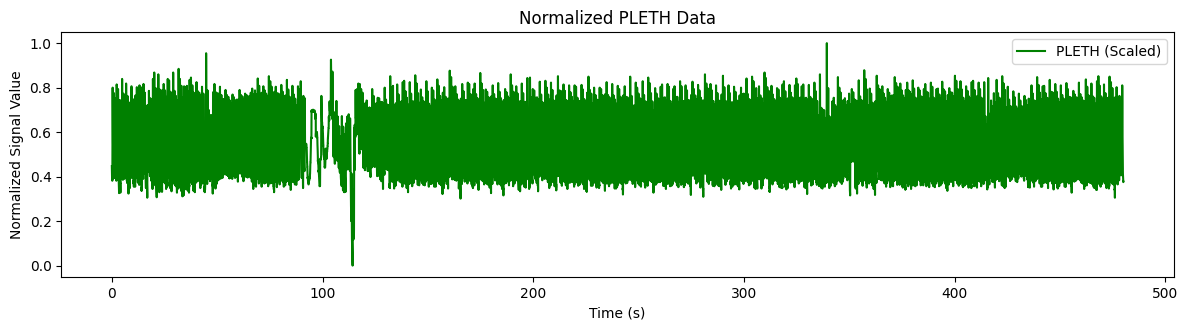

In [38]:
# Vẽ lại sau khi chuẩn hóa

plt.figure(figsize=(12, 6))
plt.subplot(2, 1, 1)
plt.plot(breaths_normalized.index, breaths_normalized.iloc[:, 0], label="Breath Ann1 (Normalized)", color='b')
plt.plot(breaths_normalized.index, breaths_normalized.iloc[:, 1], label="Breath Ann2 (Normalized)", color='r')
plt.xlabel("Index")
plt.ylabel("Normalized Value")
plt.title("Normalized Breaths Data")
plt.legend()

plt.figure(figsize=(12, 6))
plt.subplot(2, 1, 1)
plt.plot(numerics_scaled['Time'], numerics_scaled['HR'], label='HR (Scaled)', color='r')
plt.xlabel('Time (s)')
plt.ylabel('Normalized Value')
plt.legend()
plt.title('Normalized HR Data')

plt.figure(figsize=(12, 6))
plt.subplot(2, 1, 1)
plt.plot(numerics_scaled['Time'], numerics_scaled['RESP'], label='RESP (Scaled)', color='b')
plt.xlabel('Time (s)')
plt.ylabel('Normalized Value')
plt.legend()
plt.title('Normalized RESP Data')

plt.figure(figsize=(12, 6))
plt.subplot(2, 1, 1)
plt.plot(numerics_scaled['Time'], numerics_scaled['SpO2'], label='SpO2 (Scaled)', color='g')
plt.xlabel('Time (s)')
plt.ylabel('Normalized Value')
plt.legend()
plt.title('Normalized SpO2 Data')

plt.figure(figsize=(12, 6))
plt.subplot(2, 1, 2)
plt.plot(signals_scaled['Time'], signals_scaled['RESP'], label='RESP (Scaled)', color='b')
plt.xlabel('Time (s)')
plt.ylabel('Normalized Signal Value')
plt.legend()
plt.title('Normalized RESP Data')

plt.figure(figsize=(12, 6))
plt.subplot(2, 1, 2)
plt.plot(signals_scaled['Time'], signals_scaled['PLETH'], label='PLETH (Scaled)', color='g')
plt.xlabel('Time (s)')
plt.ylabel('Normalized Signal Value')
plt.legend()
plt.title('Normalized PLETH Data')

plt.tight_layout()
plt.show()